In [1]:
import pandas as pd
import tqdm
import codepub as cdp
import time
import math

import seaborn as sn
from matplotlib import pyplot as plt
import matplotlib.patches as mpatches

# Figure 1: Algorithm statistics

## A
Interaction between the number of peptides, the number of pools, and peptide occurrence parameters in the CPP.

100%|██████████| 5/5 [00:00<00:00, 511.66it/s]


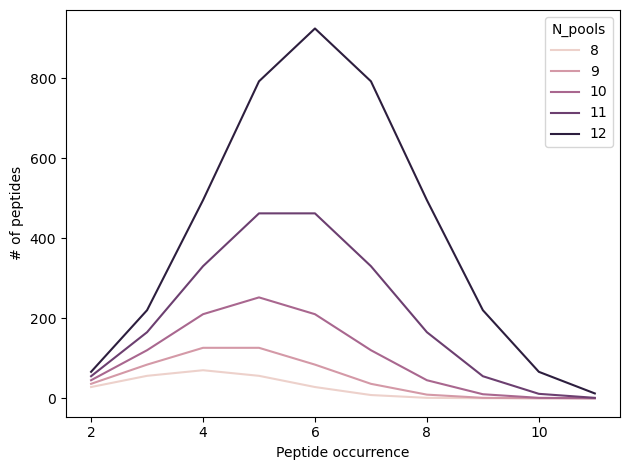

In [2]:
data = pd.DataFrame(columns = ['N_pools', 'Peptide occurrence', '# of peptides'])

for n in tqdm.tqdm(range(8, 13)):
    for i in range(2, 12):
        row = pd.DataFrame({'N_pools':n, 'Peptide occurrence':i, '# of peptides':math.comb(n, i)}, index=[0])
        data = pd.concat([data, row])

sn.lineplot(data = data, x='Peptide occurrence', y='# of peptides', hue = 'N_pools')

plt.tight_layout()

## B
Empirical runtime analyses showing that the codepub rcBBA algorithm
depends on the number of pools and peptides (displayed for constant number of pools per peptide = 4).

In [3]:
results_time_fixI4 = pd.DataFrame(columns = ['N_pools', '# of peptides', 'Time (s)'])

for n in range(15, 20):
    results_time = dict()
    for i in tqdm.tqdm(range(50, 1000, 10)):
        start_time = time.time()
        b, lines = cdp.rcbba(m=n, r=4, n=i)
        end_time = time.time()
        elapsed_time = end_time - start_time
        results_time[i] = elapsed_time
    results_time = pd.DataFrame.from_dict(results_time, orient = 'index')
    results_time = results_time.reset_index()
    results_time.columns = ['# of peptides', 'Time (s)']
    results_time['N_pools'] = n
    results_time_fixI4  = pd.concat([results_time_fixI4, results_time])

100%|██████████| 95/95 [01:01<00:00,  1.54it/s]
/var/folders/bb/6j1bt4dj4x15t9jtm7vlh6gh0000gp/T/ipykernel_27409/1681342960.py:15: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  results_time_fixI4  = pd.concat([results_time_fixI4, results_time])
100%|██████████| 95/95 [01:23<00:00,  1.14it/s]


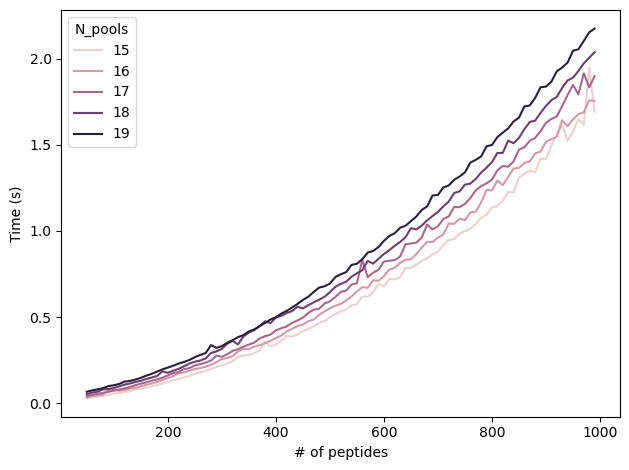

In [4]:
sn.lineplot(data = results_time_fixI4, x = '# of peptides', y = 'Time (s)', hue = 'N_pools')

plt.tight_layout()

## C
Deviation of
codepub-derived experimental balance (Balance_actual) from optimal balance (Balance_perfect). The difference is displayed
for a simulation of 16 pools and a constant number of pools per peptide = 4. For the number of peptides ≤ 50, the BBA
algorithm was applied, and for experimental setups with the number of peptides > 50, rcBBA was used.

In [5]:
results_balance_fixN16_fixI4 = dict()
for i in tqdm.tqdm(range(50, 1000, 100)):
    b, lines = cdp.bba(m=16, r=4, n=i)
    results_balance_fixN16_fixI4[i] = b
balance = pd.DataFrame.from_dict(results_balance_fixN16_fixI4, orient = 'index')

balance['perfect'] = 0
for i in list(balance.index):
    balance.loc[i, 'perfect'] = int(i*4/16)

for i in list(balance.index):
    for y in balance.columns:
        if y != 'perfect':
            balance.loc[i, y] = balance.loc[i, y] - balance.loc[i, 'perfect']


results_balance_fixN16_fixI4_rca = dict()
for i in tqdm.tqdm(range(50, 1000, 100)):
    b, lines = cdp.rcbba(m=16, r=4, n=i)
    results_balance_fixN16_fixI4_rca[i] = b
balance_rca = pd.DataFrame.from_dict(results_balance_fixN16_fixI4_rca, orient = 'index')

balance_rca['perfect'] = 0
for i in list(balance_rca.index):
    balance_rca.loc[i, 'perfect'] = int(i*4/16)

for i in list(balance_rca.index):
    for y in balance_rca.columns:
        if y != 'perfect':
            balance_rca.loc[i, y] = balance_rca.loc[i, y] - balance_rca.loc[i, 'perfect']

100%|██████████| 10/10 [00:06<00:00,  1.50it/s]


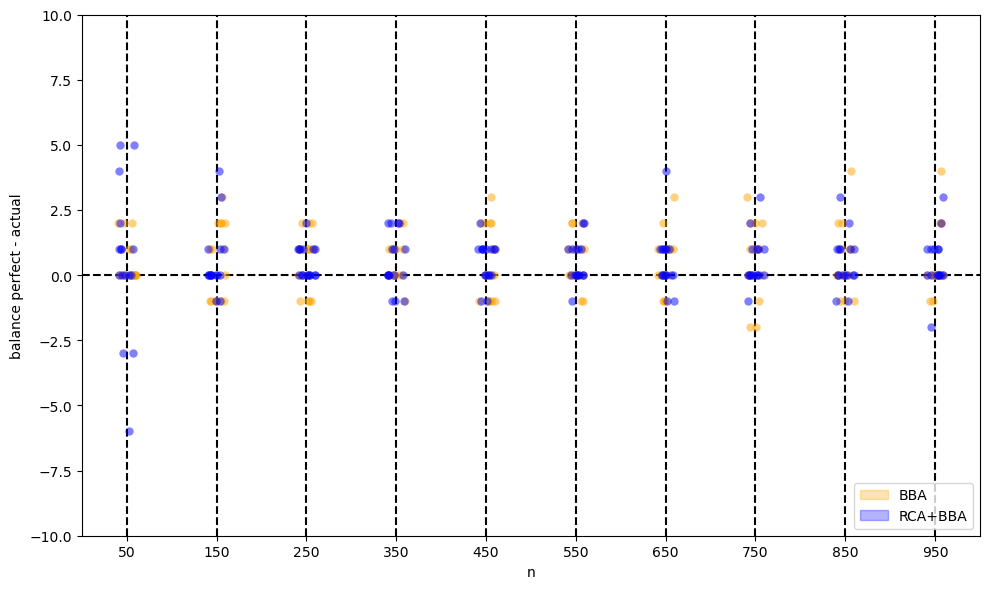

In [6]:
## balance distributions plot
balance_range = []
for i in range(len(balance.drop('perfect', axis=1))):
    balance_range.append(list(balance.drop('perfect', axis=1)[i]))
balance_range_bba = [x for xs in balance_range for x in xs]


balance_range = []
for i in range(len(balance_rca.drop('perfect', axis=1))):
    balance_range.append(list(balance_rca.drop('perfect', axis=1)[i]))
balance_range_rca = [x for xs in balance_range for x in xs]

fig, ax_scatter = plt.subplots(figsize=(10, 6))

sn.stripplot(data=balance.drop('perfect', axis=1).T, jitter=0.1, size=6, color='orange', alpha=0.5, ax=ax_scatter)
sn.stripplot(data=balance_rca.drop('perfect', axis=1).T, jitter=0.1, size=6, color='blue', alpha=0.5, ax=ax_scatter)

ax_scatter.axhline(0, ls='--', color='black')

for x in range(10):
    ax_scatter.axvline(x, ls='--', color='black')

ax_scatter.set_ylim(-10, 10)
ax_scatter.set_xlabel('n')
ax_scatter.set_ylabel('balance perfect - actual')

patch_bba = mpatches.Patch(color='orange', alpha=0.3, label='BBA')
patch_rca = mpatches.Patch(color='blue', alpha=0.3, label='RCA+BBA')
ax_scatter.legend(handles=[patch_bba, patch_rca], loc='lower right')

plt.tight_layout()
plt.show()